# Macaque single cell data

In [1]:
from __future__ import annotations
import time
from pathlib import Path 
import numpy as np
import torch
import torch.nn as nn
import sys
import medal
import umap

## Prepare data

Mixed subject batches on M1 reference manifold: data integration in-distribution v out-of-distribution.

In [17]:
# 0. Prepare data: split training data of M1, mix batch of M1 and M2. 
import pandas as pd
mac1 = pd.read_csv('../data/macaque IG/macaque1_hvg3000.csv.gz')
mac2 = pd.read_csv('../data/macaque IG/macaque2_hvg3000.csv.gz')

In [42]:
mac1.head()

,LOC102117280,LYPD8,LOC102140806,LOC102115026,LOC102123824,LOC102138413,LOC102141073,LOC102144693,LOC107128892,LOC102139797,...,LOC102117148,LOC102125235,LOC102130876,LOC102136222,CETN2,PNCK,LOC102131120,MSTRG.23238,labels,mac
0,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0.0,0.0,0,0.0,0.00000,0.0,0.0,0.0,Cones,M1
1,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0.0,0.0,0,0.0,1.91219,0.0,0.0,0.0,HC,M1
2,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0.0,0.0,0,0.0,0.00000,0.0,0.0,0.0,MG,M1
3,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0.0,0.0,0,0.0,2.15084,0.0,0.0,0.0,MG,M1
4,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0.0,0.0,0,0.0,0.00000,0.0,0.0,0.0,Cones,M1


In [20]:
X1 = mac1.iloc[:,:-2].copy()
X2 = mac2.iloc[:, :-2].copy()

In [32]:
X1.head()

,LOC102117280,LYPD8,LOC102140806,LOC102115026,LOC102123824,LOC102138413,LOC102141073,LOC102144693,LOC107128892,LOC102139797,...,LOC102141043,LOC107128557,LOC102117148,LOC102125235,LOC102130876,LOC102136222,CETN2,PNCK,LOC102131120,MSTRG.23238
0,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0,0.0,0.0,0.0,0,0.0,0.00000,0.0,0.0,0.0
1,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0,0.0,0.0,0.0,0,0.0,1.91219,0.0,0.0,0.0
2,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0,0.0,0.0,0.0,0,0.0,0.00000,0.0,0.0,0.0
3,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0,0.0,0.0,0.0,0,0.0,2.15084,0.0,0.0,0.0
4,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,0.0,...,0,0.0,0.0,0.0,0,0.0,0.00000,0.0,0.0,0.0


In [74]:
import scanpy as sc
from scipy.sparse import csr_matrix
import anndata as ad
adata1 = ad.AnnData(csr_matrix(X1.astype(np.float32)))
adata1.var_names = X1.columns

In [75]:
adata1.obs['labels'] = mac1['labels'].to_numpy()
adata1.obs['macaque'] = mac1['mac'].to_numpy()

In [73]:
adata2 = ad.AnnData(csr_matrix(X2.astype(np.float32)))
adata2.var_names = X2.columns
adata2.obs['labels'] = mac2['labels'].to_numpy()
adata2.obs['macaque'] = mac2['mac'].to_numpy()

In [130]:
adata = ad.concat([adata1, adata2], axis='obs')

/burg-archive/stats/users/cmh2277/.conda/envs/medal_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [131]:
adata.obs_names_make_unique()

In [132]:
# Define the train test split, set all M2 as test, 0.1 of M1 as test
adata.obs['split'] = 'train'
adata.obs.loc[adata.obs['macaque']=='M2', 'split'] = 'test'
# 0.1 of M1 as test
m1_test_idx = np.random.choice(48000, size=int(48000* 0.1), replace=False)
mask = (adata.obs['macaque']=='M1') & (adata.obs_names.isin([str(i) for i in m1_test_idx]))
adata.obs.loc[mask,'split'] = 'test'

In [133]:
adata.write_h5ad('../data/macaque IG/m1_train_m1m2_mixbatch_test.h5ad')

## Load trained MEDAL

Architecture search and training in `train_macaque.py`. Teacher used is a custom PC100+UMAP teacher.

In [3]:
import sys
sys.path.append("../MEDAL-custom/src/")
import medal
from medal.io import load_model

In [10]:
from pathlib import Path
import json
from medal.normalizer import GlobalEmbeddingNormalizer
import numpy as np

SOURCE = Path('./mac_experiments/custom_arch')
cfg = json.loads((SOURCE/'best_config.json').read_text())['best_config']
X_train = np.load(SOURCE / 'X_train.npy').astype('float32')
X_val = np.load(SOURCE / 'X_val.npy').astype('float32')
raw = np.load(SOURCE/'embeddings/arch_search_teacher.npy')
norm = GlobalEmbeddingNormalizer.load(SOURCE / 'embeddings/arch_search_teacher.norm.pkl')

### Teacher embedding

In [19]:
import scanpy as sc
adata = sc.read_h5ad('../data/macaque IG/m1_train_m1m2_mixbatch_test.h5ad')
adata

AnnData object with n_obs × n_vars = 96000 × 3000
    obs: 'labels', 'macaque', 'split'

In [25]:
cell_type_train = adata[adata.obs.split == 'train',:].obs['labels']

In [51]:
train_idx = np.load(SOURCE / 'idx_train.npy').astype('float32')
val_idx = np.load(SOURCE / 'idx_val.npy').astype('float32')

In [34]:
X_test = adata[np.flatnonzero((adata.obs['split']=='test').to_numpy()),:].X.toarray().astype('float32')

In [35]:
X_train.shape, X_val.shape, X_test.shape

((34560, 3000), (8640, 3000), (52800, 3000))

In [16]:
Z = norm.transform(raw)

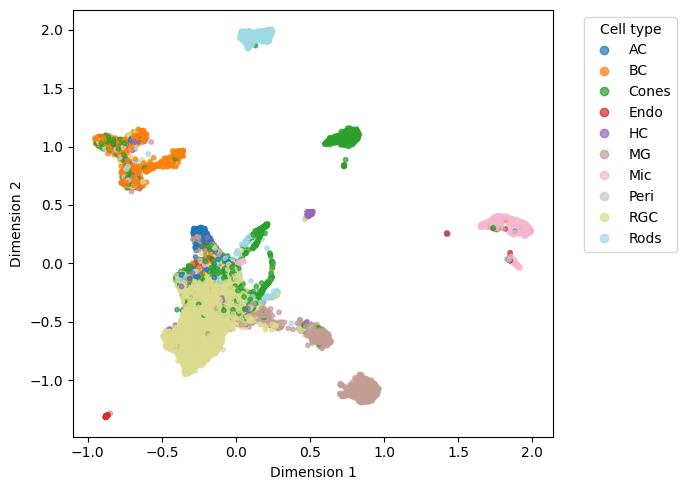

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

labels = pd.Categorical(cell_type_train.iloc[train_idx])

plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    Z[:, 0], Z[:, 1],
    c=labels.codes,
    cmap="tab20",
    s=10,
    alpha=0.7
)

# Legend with actual cell type names
handles, _ = scatter.legend_elements()
plt.legend(
    handles,
    labels.categories,
    title="Cell type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.tight_layout()
plt.show()

In [36]:
from pathlib import Path
import numpy as np
import medal

output_dir = Path("mac_experiments/custom_sweep")

sweep = medal.SweepResults.load(output_dir)
df = sweep.load_metrics(X_test)
opt_param = medal.select_teacher_param(df, param_col=sweep.param_name,)
seed = 0 
# Uses the saved custom configuration manifest.
tc, embedding_path, normalizer_path, ckpt = sweep._artifacts(opt_param, seed)

ac = sweep.arch_config
X_train_saved = np.load(output_dir / "X_train.npy", mmap_mode="r")

model = medal.load_model(
    ckpt_path=ckpt,
    input_dim=X_train_saved.shape[1],
    hidden_dims=tuple(ac["hidden_dims"]),
    latent_dim=tc.get("n_components", sweep.n_components),
    activation=ac.get("activation", "SELU"),
    use_batchnorm=ac.get("use_batchnorm", False),
    dropout_rate=ac.get("dropout_rate", 0.0),
    bottleneck_activation=ac.get("bottleneck_activation"),
    final_activation=ac.get("final_activation"),
)

print("Checkpoint:", ckpt)
print(f"Selected {sweep.param_name}: {opt_param}; seed: {seed}")

Checkpoint: mac_experiments/custom_sweep/medal___custom__92abc52a4dbeef2f6aa6_60b3b0afd560fa4c609e_seed0_ckpts/final.pt
Selected n_neighbors: 58; seed: 0


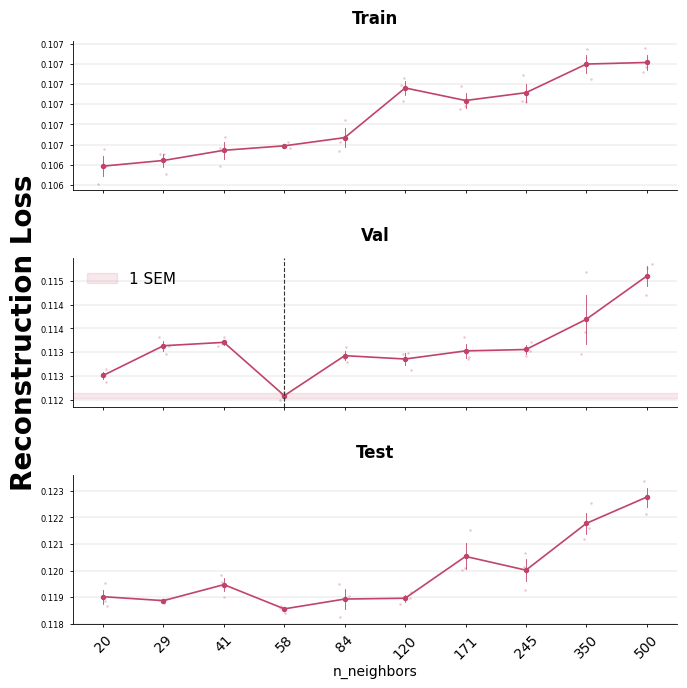

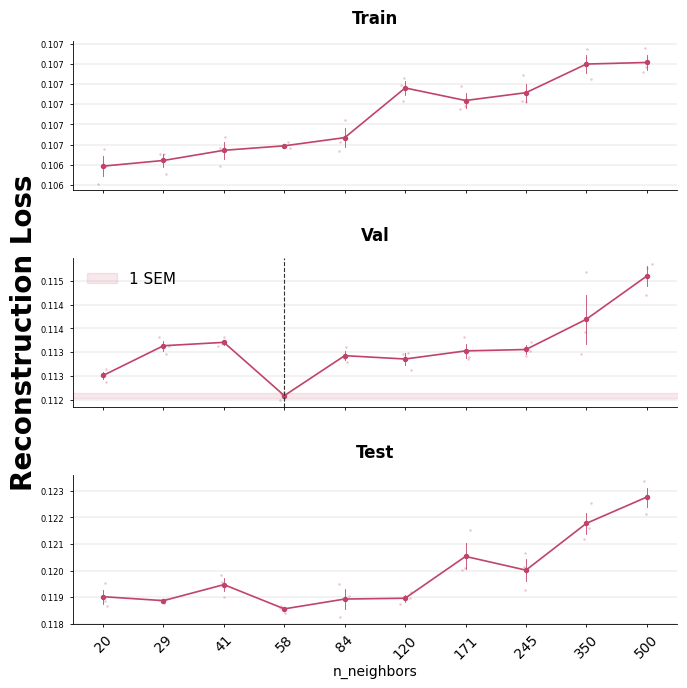

In [44]:
medal.plot_reconstruction_error(df, opt_param, param_col="n_neighbors")

In [52]:
labels_train = pd.Categorical(cell_type_train.iloc[train_idx]).codes
labels_val = pd.Categorical(cell_type_train.iloc[val_idx]).codes


In [59]:
pd.Categorical(cell_type_train).codes

array([2, 4, 5, ..., 8, 8, 4], shape=(43200,), dtype=int8)

In [ ]:
emb_data = sweep.load_embeddings(
    pd.Categorical(cell_type_train).codes,
    X_val,
    labels_val,
    params=[opt_param],   # load only the optimal hyperparameter to keep it fast
)

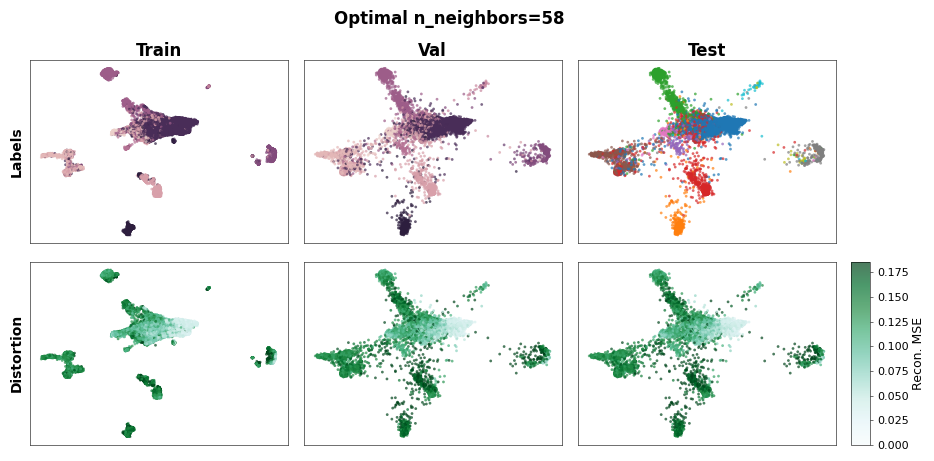

In [61]:
fig = medal.plot_distortion_map(
    emb_data,
    opt_param,
    param_col="n_neighbors",
    param="best",
    cmap="BuGn"
)

In [38]:
Z_test = medal.embed(model, X_test)

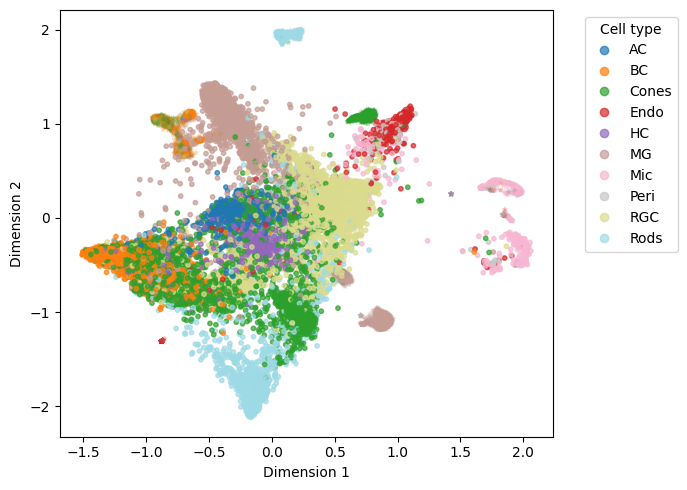

In [42]:
labels_test = pd.Categorical(adata[adata.obs['split']=='test',:].obs['labels'])

plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    Z[:, 0], Z[:, 1],
    c=labels.codes,
    cmap="tab20",
    s=10,
    alpha=0.2,
    marker='*'
)

scatter = plt.scatter(
    Z_test[:, 0], Z_test[:, 1],
    c=labels_test.codes,
    cmap="tab20",
    s=10,
    alpha=0.7
)
# Legend with actual cell type names
handles, _ = scatter.legend_elements()
plt.legend(
    handles,
    labels.categories,
    title="Cell type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.tight_layout()
plt.show()

In [77]:
mac_id = pd.Categorical(adata[adata.obs['split']=='train',:].obs['macaque']).codes
mac_id[train_idx.astype(int)]

array([0, 0, 0, ..., 0, 0, 0], shape=(34560,), dtype=int8)

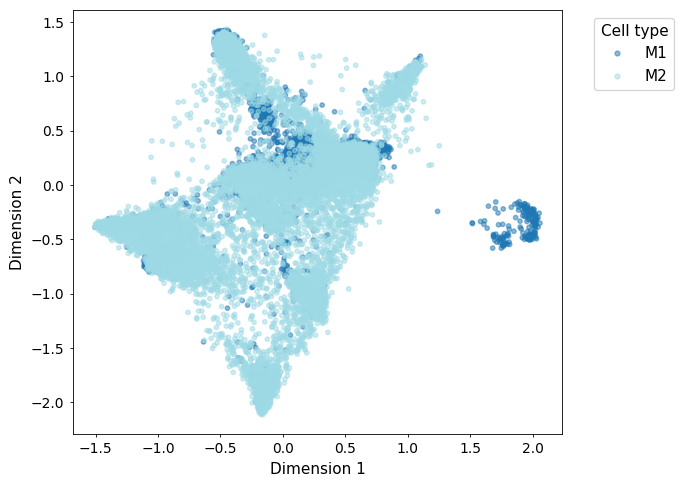

In [84]:
labels_test = pd.Categorical(adata[adata.obs['split']=='test',:].obs['macaque'])
plt.figure(figsize=(7, 5))
# scatter = plt.scatter(
#     Z[:, 0], Z[:, 1],
#     c=mac_id[train_idx.astype(int)],
#     cmap="tab20",
#     s=10,
#     alpha=0.1,
#     marker='*'
# )

scatter = plt.scatter(
    Z_test[:, 0], Z_test[:, 1],
    c=labels_test.codes,
    cmap="tab20",
    s=10,
    alpha=0.5
)
# Legend with actual cell type names
handles, _ = scatter.legend_elements()
plt.legend(
    handles,
    labels_test.categories,
    title="Cell type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.tight_layout()
plt.show()

In [95]:
# Wrapper to compute integrated gradients 
from captum.attr import IntegratedGradients
import torch
import torch.nn as nn

class _Encoder(nn.Module):
    """x -> encoder latent (batch, 2)."""
    def __init__(self, model):
        super().__init__()
        self.encoder = model.encoder
    def forward(self, x):
        return self.encoder(x)


class _Autoencoder(nn.Module):
    """x -> reconstruction (batch, INPUT_DIM)."""
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        return self.model(x)[0]


class _ReconLoss(nn.Module):
    """x -> per-sample reconstruction MSE (batch,)."""
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        x_recon = self.model(x)[0]
        return ((x - x_recon) ** 2).mean(dim=1)

# ---------------------------------------------------------------------------
# Experiment 1: Encoder IG
# ---------------------------------------------------------------------------

def run_encoder_ig(model, X_test):
    print("=== Experiment 1: Encoder IG ===")
    t0 = time.time()

    ig = IntegratedGradients(_Encoder(model))

    n = N_SAMPLES if N_SAMPLES is not None else len(X_test)
    if n < len(X_test):
        rng = np.random.RandomState(42)
        idx = rng.choice(len(X_test), size=n, replace=False)
        x_batch = torch.tensor(X_test[idx], dtype=torch.float32, device=DEVICE)
    else:
        x_batch = torch.tensor(X_test, dtype=torch.float32, device=DEVICE)
    baseline = torch.zeros_like(x_batch)

    attr_z1 = ig.attribute(x_batch, baselines=baseline, target=0,
                           n_steps=IG_STEPS,
                           internal_batch_size=len(x_batch))
    attr_z2 = ig.attribute(x_batch, baselines=baseline, target=1,
                           n_steps=IG_STEPS,
                           internal_batch_size=len(x_batch))

    importance = (attr_z1.abs() + attr_z2.abs()).cpu().numpy()  # (N, 100)
    avg_map = importance.mean(axis=0)  # (100,)
    print(f"  Done in {time.time()-t0:.1f}s  ({len(x_batch)} samples)")
    assert np.all(np.isfinite(avg_map)), "Non-finite attribution values!"
    return avg_map, importance, attr_z1, attr_z2

In [96]:
N_SAMPLES = None
DEVICE = 'cpu'
IG_STEPS = 50
avg_map, importance, attr_z1, attr_z2 = run_encoder_ig(model, X_test)

=== Experiment 1: Encoder IG ===
  Done in 263.0s  (52800 samples)


In [97]:
np.savez('./mac_experiments/ig_attribution_data.npz',
         encoder_ig = avg_map,
         l1_imp = importance,
         attr_z1 = attr_z1,
         attr_z2 = attr_z2)


### Test genes mapped

In [125]:
top100_genes = adata[adata.obs.split=='test',avg_map.argsort()[::-1]].var.head(100)

In [126]:
imp_scores = avg_map[avg_map.argsort()[::-1]][:100]

In [131]:
top100_genes['importance'] = imp_scores

In [141]:
top100_genes = top100_genes.reset_index(names='genes')

<BarContainer object of 10 artists>

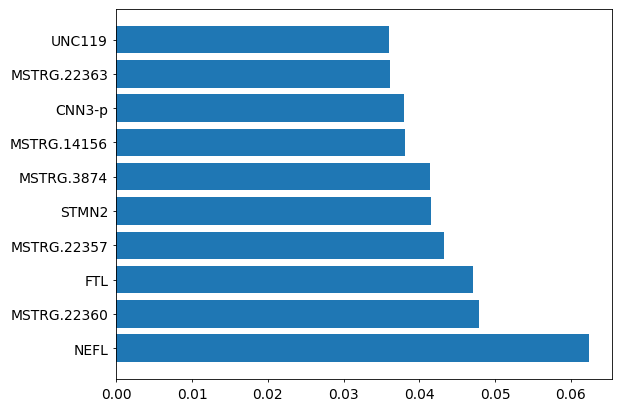

In [145]:
plt.barh(top100_genes['genes'][:10],top100_genes['importance'][:10])

### In sample genes

In [147]:
N_SAMPLES = None
DEVICE = 'cpu'
IG_STEPS = 50
avg_map, importance, attr_z1, attr_z2 = run_encoder_ig(model, X_train)

=== Experiment 1: Encoder IG ===
  Done in 61.5s  (34560 samples)


In [148]:
np.savez('./mac_experiments/ig_attribution_data_train.npz',
         encoder_ig = avg_map,
         l1_imp = importance,
         attr_z1 = attr_z1,
         attr_z2 = attr_z2)


In [149]:
top100_genes = adata[adata.obs.split=='train',avg_map.argsort()[::-1]].var.head(100)

In [150]:
imp_scores = avg_map[avg_map.argsort()[::-1]][:100]
top100_genes['importance'] = imp_scores
top100_genes = top100_genes.reset_index(names='genes')

<BarContainer object of 10 artists>

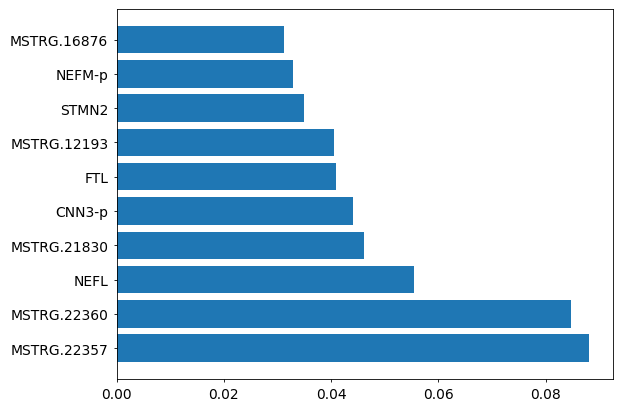

In [151]:
plt.barh(top100_genes['genes'][:10],top100_genes['importance'][:10])

In [159]:
df = sweep.load_metrics(X_train)
df.head()

,n_neighbors,seed,split,recon_loss,distill_mse
0,20,0,Train,0.106307,0.000002
1,20,0,Val,0.112497,NaN
2,20,0,Test,0.106307,NaN
3,20,1,Train,0.106480,0.000008
4,20,1,Val,0.112379,NaN


In [162]:
df[df.n_neighbors==58]

,n_neighbors,seed,split,recon_loss,distill_mse
27,58,0,Train,0.106485,0.000004
28,58,0,Val,0.112114,NaN
29,58,0,Test,0.106485,NaN
30,58,1,Train,0.106486,0.000005
31,58,1,Val,0.112162,NaN
32,58,1,Test,0.106486,NaN
33,58,2,Train,0.106511,0.000005
34,58,2,Val,0.111987,NaN
35,58,2,Test,0.106511,NaN
